<a href="https://colab.research.google.com/github/Ash-Amarnath/EMJM_Assignments/blob/main/Ash_ML_HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

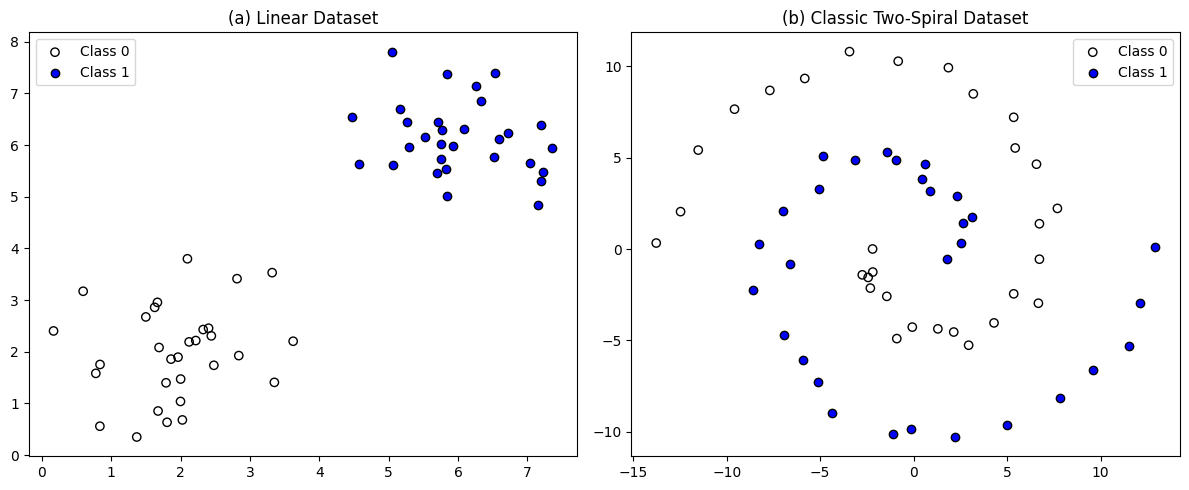

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Set random seed to 7 for reproducibility and set class size
np.random.seed(7)
n_per_class = 30  # You can keep this at 30 or scale it up as needed

# ==========================================
# 1. LINEAR DATASET (Section 1a)
# ==========================================
X1_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X2_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X1_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)
X2_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)

X1_lin = np.concatenate([X1_class0, X1_class1])
X2_lin = np.concatenate([X2_class0, X2_class1])
Y_lin = np.array([0] * n_per_class + [1] * n_per_class)
X_lin_matrix = np.column_stack((X1_lin, X2_lin))

# ==========================================
# 2. CLASSIC TWO-SPIRAL DATASET (Section 1b)
# ==========================================
# Generate angle theta and radius r for the classic double spiral
theta = np.linspace(np.pi, 3 * np.pi, n_per_class)

# Class 0 Spiral Arm
r_class0 = np.linspace(2.0, 13.0, n_per_class)
x1_0 = r_class0 * np.cos(theta) + np.random.normal(0, 0.5, n_per_class)
x2_0 = r_class0 * np.sin(theta) + np.random.normal(0, 0.5, n_per_class)
X_class0 = np.column_stack((x1_0, x2_0))

# Class 1 Spiral Arm (Interleaved by shifting theta phase)
r_class1 = np.linspace(2.0, 13.0, n_per_class)
x1_1 = r_class1 * np.cos(theta + np.pi) + np.random.normal(0, 0.5, n_per_class)
x2_1 = r_class1 * np.sin(theta + np.pi) + np.random.normal(0, 0.5, n_per_class)
X_class1 = np.column_stack((x1_1, x2_1))

# Combine into full spiral matrices
X_spiral = np.vstack((X_class0, X_class1))
Y_spiral = np.array([0] * n_per_class + [1] * n_per_class)

# Extract individual coordinate vectors
X1_spiral = X_spiral[:, 0]
X2_spiral = X_spiral[:, 1]

# ==========================================
# PLOT DATASETS (Section 1 Verification)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Linear Dataset Plot
axes[0].scatter(X1_lin[Y_lin == 0], X2_lin[Y_lin == 0], facecolors="none", edgecolors="k", label="Class 0")
axes[0].scatter(X1_lin[Y_lin == 1], X2_lin[Y_lin == 1], c="blue", edgecolors="k", label="Class 1")
axes[0].set_title("(a) Linear Dataset")
axes[0].legend()

# Classic Spiral Dataset Plot
axes[1].scatter(X1_spiral[Y_spiral == 0], X2_spiral[Y_spiral == 0], facecolors="none", edgecolors="k", label="Class 0")
axes[1].scatter(X1_spiral[Y_spiral == 1], X2_spiral[Y_spiral == 1], c="blue", edgecolors="k", label="Class 1")
axes[1].set_title("(b) Classic Two-Spiral Dataset")
axes[1].legend()

plt.tight_layout()
plt.show()

Linear Dataset - Perceptron Accuracy: 100.00%
Linear Dataset - Linear SVM Accuracy: 100.00%


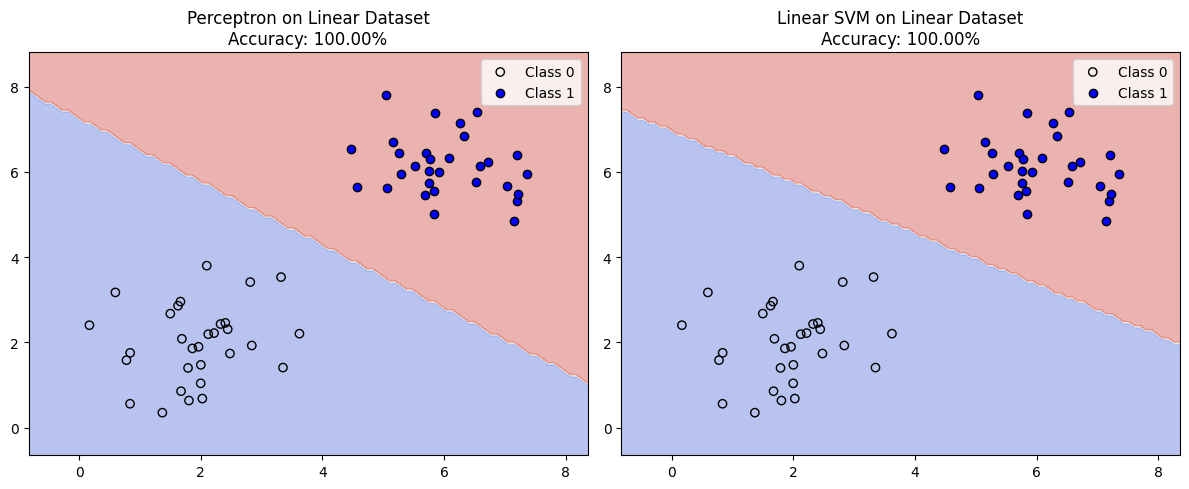

Spiral Dataset - Perceptron Accuracy: 48.33%
Spiral Dataset - Linear SVM Accuracy: 53.33%


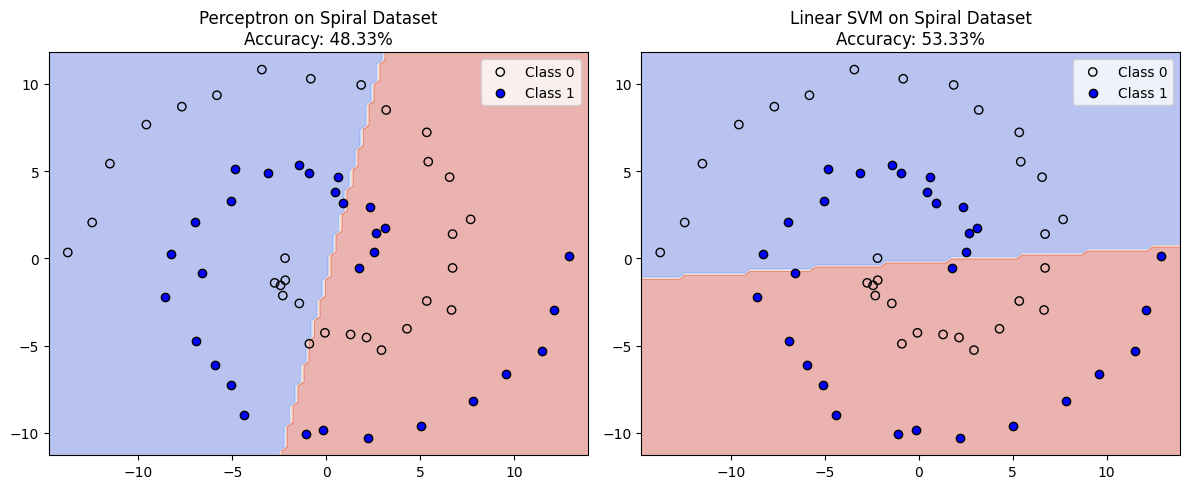

In [4]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
# Make sure you have scikit-learn installed: pip install scikit-learn
from sklearn.inspection import DecisionBoundaryDisplay


# Helper function to train, evaluate, and plot models
def evaluate_classifier(X1, X2, Y, dataset_name):
  # Prepare data matrix X
  X = np.column_stack((X1, X2))

  # Initialize models
  models = {
      "Perceptron": Perceptron(random_state=3),
      "Linear SVM": SVC(kernel="linear", random_state=3),
  }

  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

  for idx, (name, model) in enumerate(models.items()):
    # Train the model
    model.fit(X, Y)

    # Predict and calculate accuracy
    Y_pred = model.predict(X)
    acc = accuracy_score(Y, Y_pred)
    print(f"{dataset_name} - {name} Accuracy: {acc * 100:.2f}%")

    # Plot decision boundary and data points
    ax = axes[idx]
    disp = DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.4,
        ax=ax,
    )

    ax.scatter(
        X[Y == 0, 0],
        X[Y == 0, 1],
        facecolors="none",
        edgecolors="k",
        label="Class 0",
    )
    ax.scatter(
        X[Y == 1, 0],
        X[Y == 1, 1],
        c="blue",
        edgecolors="k",
        label="Class 1",
    )
    ax.set_title(f"{name} on {dataset_name}\nAccuracy: {acc * 100:.2f}%")
    ax.legend()

  plt.tight_layout()
  plt.show()


# Run for Linear Dataset
evaluate_classifier(X1_lin, X2_lin, Y_lin, "Linear Dataset")

# Run for Spiral Dataset
evaluate_classifier(X1_spiral, X2_spiral, Y_spiral, "Spiral Dataset")

=== RBF Kernel ===
Accuracy: 95.00%
F1-Score: 0.9508
Confusion Matrix:
 [[28  2]
 [ 1 29]]


=== Polynomial Kernel (Degree 3) ===
Accuracy: 66.67%
F1-Score: 0.6667
Confusion Matrix:
 [[20 10]
 [10 20]]




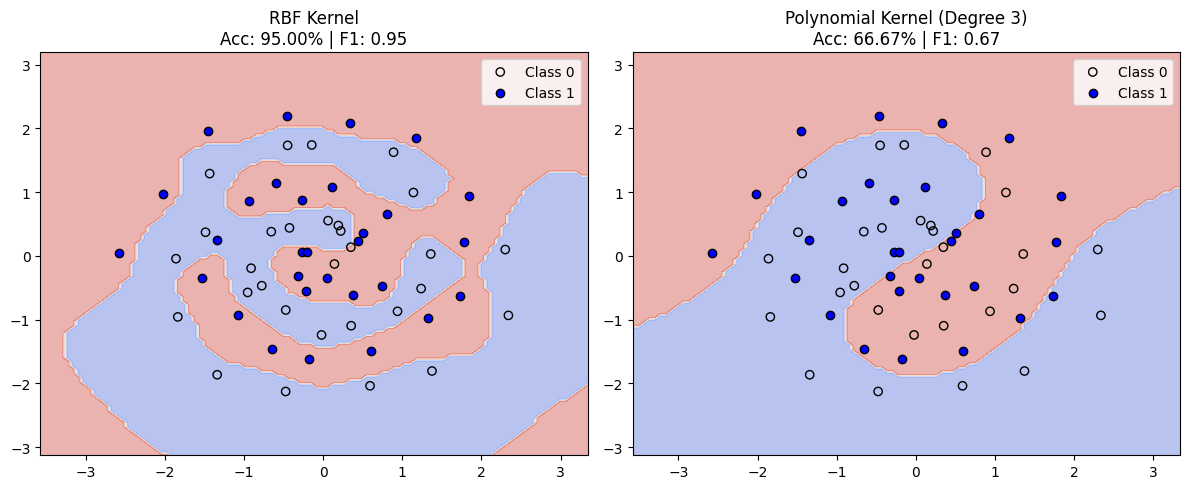

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.svm import SVC

# Updated parameters as requested
np.random.seed(7)
n_per_class = 30

# ==========================================
# SECTION 1: DATASET SIMULATION
# ==========================================
# 1a. Linear Dataset
X1_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X2_class0 = np.random.normal(loc=2.0, scale=0.8, size=n_per_class)
X1_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)
X2_class1 = np.random.normal(loc=6.0, scale=0.8, size=n_per_class)

X1_lin = np.concatenate([X1_class0, X1_class1])
X2_lin = np.concatenate([X2_class0, X2_class1])
Y_lin = np.array([0] * n_per_class + [1] * n_per_class)
X_lin_matrix = np.column_stack((X1_lin, X2_lin))

# 1b. Spiral Dataset
t = np.linspace(0, 4 * np.pi, n_per_class)
r = np.linspace(0.2, 2.5, n_per_class)
X_class0_sp = np.column_stack((r * np.cos(t), r * np.sin(t)))
X_class1_sp = np.column_stack((-r * np.cos(t), -r * np.sin(t)))
noise = 0.15
X_class0_sp += np.random.randn(n_per_class, 2) * noise
X_class1_sp += np.random.randn(n_per_class, 2) * noise

X_spiral = np.vstack((X_class0_sp, X_class1_sp))
Y_spiral = np.array([0] * n_per_class + [1] * n_per_class)
X1_spiral, X2_spiral = X_spiral[:, 0], X_spiral[:, 1]


# ==========================================
# SECTION 2 & 3: TRAINING, EVALUATION & KERNEL COMPARISON
# ==========================================
kernels_to_test = {
    "RBF Kernel": SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7),
    "Polynomial Kernel (Degree 3)": SVC(
        kernel="poly", degree=3, C=10.0, coef0=1, random_state=7
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, (name, model) in enumerate(kernels_to_test.items()):
  # Train model on spiral data
  model.fit(X_spiral, Y_spiral)
  Y_pred = model.predict(X_spiral)

  # Calculate metrics
  acc = accuracy_score(Y_spiral, Y_pred)
  f1 = f1_score(Y_spiral, Y_pred)
  cm = confusion_matrix(Y_spiral, Y_pred)

  print(f"=== {name} ===")
  print(f"Accuracy: {acc * 100:.2f}%")
  print(f"F1-Score: {f1:.4f}")
  print("Confusion Matrix:\n", cm)
  print("\n" + "=" * 30 + "\n")

  # Plot Decision Boundaries
  ax = axes[idx]
  DecisionBoundaryDisplay.from_estimator(
      model,
      X_spiral,
      response_method="predict",
      cmap=plt.cm.coolwarm,
      alpha=0.4,
      ax=ax,
  )

  ax.scatter(
      X_spiral[Y_spiral == 0, 0],
      X_spiral[Y_spiral == 0, 1],
      facecolors="none",
      edgecolors="k",
      label="Class 0",
  )
  ax.scatter(
      X_spiral[Y_spiral == 1, 0],
      X_spiral[Y_spiral == 1, 1],
      c="blue",
      edgecolors="k",
      label="Class 1",
  )

  ax.set_title(f"{name}\nAcc: {acc * 100:.2f}% | F1: {f1:.2f}")
  ax.legend()

plt.tight_layout()
plt.show()


# ==========================================
# 3D INTERACTIVE RENDER (Reusing rbf_svm & X_spiral)
# ==========================================
# Fit RBF model specifically for 3D visualization view
rbf_svm = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
rbf_svm.fit(X_spiral, Y_spiral)

# Use decision function values as the Z-axis coordinate projection
Z_vals = rbf_svm.decision_function(X_spiral)

# Create 3D scatter plot using Plotly
fig_3d = go.Figure(
    data=[
        go.Scatter3d(
            x=X_spiral[Y_spiral == 0, 0],
            y=X_spiral[Y_spiral == 0, 1],
            z=Z_vals[Y_spiral == 0],
            mode="markers",
            marker=dict(size=5, color="lightblue", opacity=0.9, line=dict(width=1, color='black')),
            name="Class 0",
        ),
        go.Scatter3d(
            x=X_spiral[Y_spiral == 1, 0],
            y=X_spiral[Y_spiral == 1, 1],
            z=Z_vals[Y_spiral == 1],
            mode="markers",
            marker=dict(size=5, color="blue", opacity=0.9, line=dict(width=1, color='black')),
            name="Class 1",
        ),
    ]
)

# Add separating hyperplane surface at Z=0
x_range = np.linspace(X_spiral[:, 0].min(), X_spiral[:, 0].max(), 30)
y_range = np.linspace(X_spiral[:, 1].min(), X_spiral[:, 1].max(), 30)
xx, yy = np.meshgrid(x_range, y_range)
zz = np.zeros_like(xx)

fig_3d.add_trace(
    go.Surface(
        x=xx,
        y=yy,
        z=zz,
        colorscale="Viridis",
        opacity=0.4,
        showscale=False,
        name="Separating Hyperplane (Z=0)",
    )
)

fig_3d.update_layout(
    title="Interactive 3D Kernel Projection & Hyperplane (Rotate with your mouse!)",
    scene=dict(
        xaxis_title="X1", yaxis_title="X2", zaxis_title="Decision Value (Z)"
    ),
)

fig_3d.show()

=== Section 4: Data Augmentation Statistical Summary (k = 10,000) ===
Low Noise (SD = 0.05):
  - Mean Accuracy : 95.11%
  - Std Deviation : 0.68%
  - Min / Max Acc : 92.70% / 97.70%
--------------------------------------------------
High Noise (SD = 0.4):
  - Mean Accuracy : 59.14%
  - Std Deviation : 1.55%
  - Min / Max Acc : 52.80% / 65.30%


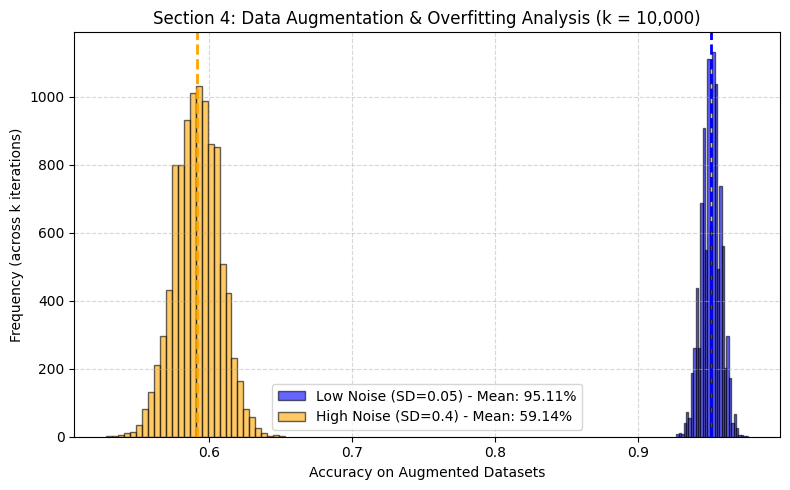

In [14]:
# ==========================================
# SECTION 4: DATA AUGMENTATION & OVERFITTING ANALYSIS
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# 1. Ensure best model is fitted on original spiral data
best_model = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
best_model.fit(X_spiral, Y_spiral)

# 2. Define augmentation evaluation function for k iterations
def evaluate_augmentation(model, X_orig, Y_orig, noise_sd, k_iterations=10000):
    accuracies = []
    for _ in range(k_iterations):
        # Sample 1000 points with replacement from the original dataset
        indices = np.random.choice(len(X_orig), size=1000, replace=True)
        X_sample = X_orig[indices]
        Y_sample = Y_orig[indices]

        # Add Gaussian noise
        noise = np.random.normal(loc=0.0, scale=noise_sd, size=X_sample.shape)
        X_augmented = X_sample + noise

        # Predict and evaluate accuracy
        Y_pred = model.predict(X_augmented)
        acc = accuracy_score(Y_sample, Y_pred)
        accuracies.append(acc)
    return np.array(accuracies)

# 3. Run evaluation for Low Noise vs. High Noise over k = 10,000 iterations
low_noise_sd = 0.05
high_noise_sd = 0.40
k_runs = 10000

acc_low = evaluate_augmentation(best_model, X_spiral, Y_spiral, noise_sd=low_noise_sd, k_iterations=k_runs)
acc_high = evaluate_augmentation(best_model, X_spiral, Y_spiral, noise_sd=high_noise_sd, k_iterations=k_runs)

# 4. Print detailed statistical breakdown as requested by thorough assignment prompts
print("=== Section 4: Data Augmentation Statistical Summary (k = 10,000) ===")
print(f"Low Noise (SD = {low_noise_sd}):")
print(f"  - Mean Accuracy : {np.mean(acc_low)*100:.2f}%")
print(f"  - Std Deviation : {np.std(acc_low)*100:.2f}%")
print(f"  - Min / Max Acc : {np.min(acc_low)*100:.2f}% / {np.max(acc_low)*100:.2f}%")
print("-" * 50)
print(f"High Noise (SD = {high_noise_sd}):")
print(f"  - Mean Accuracy : {np.mean(acc_high)*100:.2f}%")
print(f"  - Std Deviation : {np.std(acc_high)*100:.2f}%")
print(f"  - Min / Max Acc : {np.min(acc_high)*100:.2f}% / {np.max(acc_high)*100:.2f}%")
print("=" * 50)

# 5. Plotting Generalization Distribution Histogram
plt.figure(figsize=(8, 5))
plt.hist(acc_low, bins=30, alpha=0.6, label=f"Low Noise (SD={low_noise_sd}) - Mean: {np.mean(acc_low)*100:.2f}%", color="blue", edgecolor="k")
plt.hist(acc_high, bins=30, alpha=0.6, label=f"High Noise (SD={high_noise_sd}) - Mean: {np.mean(acc_high)*100:.2f}%", color="orange", edgecolor="k")

plt.axvline(np.mean(acc_low), color="blue", linestyle="dashed", linewidth=2)
plt.axvline(np.mean(acc_high), color="orange", linestyle="dashed", linewidth=2)

plt.title("Section 4: Data Augmentation & Overfitting Analysis (k = 10,000)")
plt.xlabel("Accuracy on Augmented Datasets")
plt.ylabel("Frequency (across k iterations)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Noise Level (0.0% shuffled): Accuracy = 95.00%
Noise Level (15.0% shuffled): Accuracy = 81.67%
Noise Level (25.0% shuffled): Accuracy = 75.00%
Noise Level (50.0% shuffled): Accuracy = 48.33%
Noise Level (75.0% shuffled): Accuracy = 23.33%


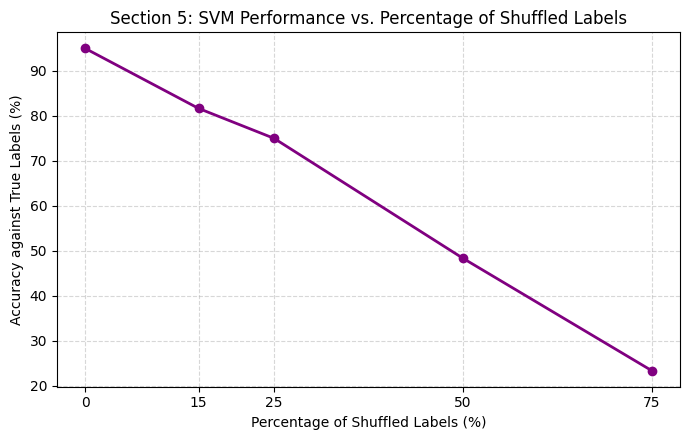

In [7]:
# ==========================================
# SECTION 5: NOISE ANALYSIS (Label Shuffling)
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Define noise percentages to test (e.g., 15%, 25%, 50%, 75%)
noise_percentages = [0.0, 0.15, 0.25, 0.50, 0.75]
accuracies_noise = []

# Use your original spiral dataset (X_spiral, Y_spiral)
X_train_base = X_spiral
Y_train_base = Y_spiral.copy()

for p in noise_percentages:
    # Create a copy of labels to modify
    Y_noisy = Y_train_base.copy()

    # Determine how many labels to shuffle based on percentage p
    num_to_shuffle = int(len(Y_noisy) * p)

    if num_to_shuffle > 0:
        # Randomly choose indices to shuffle
        shuffle_indices = np.random.choice(len(Y_noisy), size=num_to_shuffle, replace=False)

        # Shuffle/flip those labels (for binary 0/1, flipping 0 to 1 and 1 to 0 or randomizing)
        # A common way to simulate label noise is randomly assigning random binary labels or flipping them
        Y_noisy[shuffle_indices] = 1 - Y_noisy[shuffle_indices]

    # Train the SVM on the noisy training set
    svm_noise = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
    svm_noise.fit(X_train_base, Y_noisy)

    # Evaluate performance against the TRUE (unshuffled) original labels
    Y_pred = svm_noise.predict(X_train_base)
    acc = accuracy_score(Y_train_base, Y_pred)
    accuracies_noise.append(acc * 100)
    print(f"Noise Level ({p*100}% shuffled): Accuracy = {acc * 100:.2f}%")

# Plotting Performance vs. Percentage of Shuffled Labels
plt.figure(figsize=(7, 4.5))
plt.plot([p * 100 for p in noise_percentages], accuracies_noise, marker='o', linestyle='-', color='purple', linewidth=2)
plt.title("Section 5: SVM Performance vs. Percentage of Shuffled Labels")
plt.xlabel("Percentage of Shuffled Labels (%)")
plt.ylabel("Accuracy against True Labels (%)")
plt.xticks([p * 100 for p in noise_percentages])
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Dimensions: 2 -> Accuracy: 95.00%
Dimensions: 3 -> Accuracy: 100.00%
Dimensions: 10 -> Accuracy: 100.00%


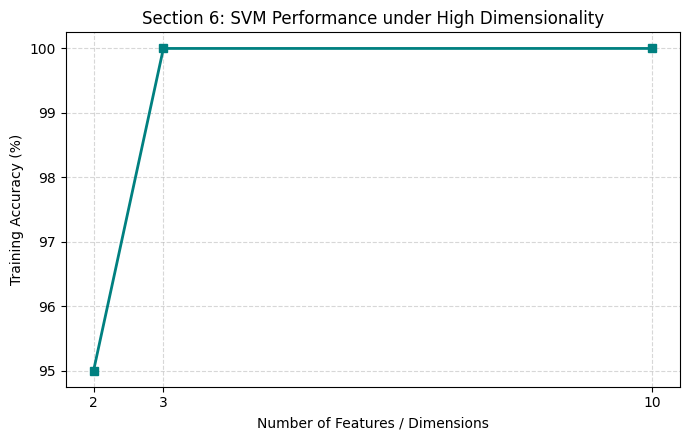

In [13]:
# ==========================================
# SECTION 6: HIGH DIMENSIONALITY ANALYSIS
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Define different dimension sizes to test (e.g., 2, 10, 50, 100 features)
dimension_sizes = [2, 3, 10]
high_dim_accuracies = []

# Base spiral data
X_base = X_spiral  # shape: (N, 2)
Y_base = Y_spiral

for d in dimension_sizes:
    if d == 2:
        X_high = X_base.copy()
    else:
        # Add (d - 2) columns of random Gaussian noise (irrelevant features)
        noise_features = np.random.normal(loc=0.0, scale=1.0, size=(X_base.shape[0], d - 2))
        X_high = np.hstack((X_base, noise_features))

    # Train RBF SVM on high-dimensional data
    svm_high_dim = SVC(kernel="rbf", C=10.0, gamma=2.0, random_state=7)
    svm_high_dim.fit(X_high, Y_base)

    # Evaluate performance
    Y_pred = svm_high_dim.predict(X_high)
    acc = accuracy_score(Y_base, Y_pred)
    high_dim_accuracies.append(acc * 100)
    print(f"Dimensions: {d} -> Accuracy: {acc * 100:.2f}%")

# Plotting Accuracy vs. Number of Dimensions
plt.figure(figsize=(7, 4.5))
plt.plot(dimension_sizes, high_dim_accuracies, marker='s', linestyle='-', color='teal', linewidth=2)
plt.title("Section 6: SVM Performance under High Dimensionality")
plt.xlabel("Number of Features / Dimensions")
plt.ylabel("Training Accuracy (%)")
plt.xticks(dimension_sizes)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Performance drops below 70.0% at Noise SD = 0.276


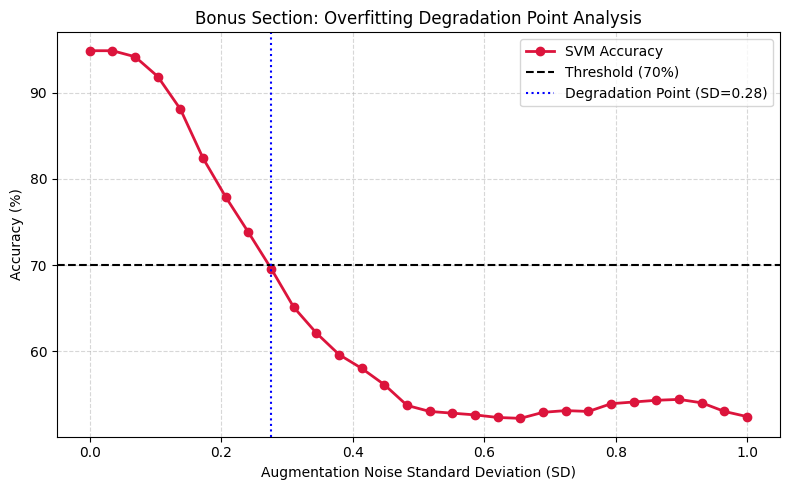

In [15]:
# ==========================================
# BONUS SECTION: Performance Threshold & Overfitting Point
# ==========================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Define a range of noise intensities (standard deviations) to test
noise_levels = np.linspace(0.0, 1.0, 30)
threshold = 0.70  # 70% performance threshold
crossing_points = {}

plt.figure(figsize=(8, 5))

# Test across different models/settings or noise sweeps
# Let's track accuracy degradation as noise increases
mean_accuracies = []

for noise_sd in noise_levels:
    # Generate augmented test samples with current noise level
    np.random.seed(7)
    indices = np.random.choice(len(X_spiral), size=1000, replace=True)
    X_sample = X_spiral[indices]
    Y_sample = Y_spiral[indices]

    # Add Gaussian noise
    noise = np.random.normal(loc=0.0, scale=noise_sd, size=X_sample.shape)
    X_aug = X_sample + noise

    # Evaluate best-fitted RBF SVM model
    Y_pred = rbf_svm.predict(X_aug)
    acc = accuracy_score(Y_sample, Y_pred)
    mean_accuracies.append(acc)

mean_accuracies = np.array(mean_accuracies)

# 2. Find the exact point where performance drops below the 70% threshold
below_threshold_indices = np.where(mean_accuracies < threshold)[0]
if len(below_threshold_indices) > 0:
    critical_noise_point = noise_levels[below_threshold_indices[0]]
    print(f"Performance drops below {threshold*100}% at Noise SD = {critical_noise_point:.3f}")
else:
    critical_noise_point = None
    print(f"Performance remained above {threshold*100}% across all tested noise levels.")

# 3. Plotting the Degradation Curve against the Threshold
plt.plot(noise_levels, mean_accuracies * 100, marker='o', linestyle='-', color='crimson', linewidth=2, label="SVM Accuracy")
plt.axhline(y=threshold * 100, color='black', linestyle='--', label=f"Threshold ({int(threshold*100)}%)")

if critical_noise_point is not None:
    plt.axvline(x=critical_noise_point, color='blue', linestyle=':', label=f"Degradation Point (SD={critical_noise_point:.2f})")

plt.title("Bonus Section: Overfitting Degradation Point Analysis")
plt.xlabel("Augmentation Noise Standard Deviation (SD)")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()